# Decision Tree

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor,plot_tree
from sklearn.ensemble import RandomForestRegressor,HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import make_scorer, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler,FunctionTransformer
from sklearn.pipeline import Pipeline

path=r'D:\python\pandas_practice\data\modified_data.csv'
df1 = pd.read_csv(path)
# df1 = df1[df1['price'] != 0]
# df1 = df1.drop(4346)
# df1 = df1.drop(4350)
# df1.to_csv(path,index=False)

pd.set_option('display.float_format', '{:,.2f}'.format)

X = df1[['bedrooms','bathrooms','sqft_living','sqft_basement','floors','yr_built','city','statezip',
         'condition','sqft_lot','sqft_above','view','waterfront','yr_renovated']]

# y = np.log(df1['price'])
y = df1['price']

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), ["city",'statezip']),
        ('log', FunctionTransformer(np.log1p),['sqft_lot'])

    ],
    remainder="passthrough"
)

model = DecisionTreeRegressor()

pipline=Pipeline([('preprocessor',preprocessor),('model',model)])

mod1 = GridSearchCV(pipline,
                   param_grid={'model__max_depth':[2,4,6,8,10,20],
                                'model__min_samples_split': [2, 5, 10],
                                'model__min_samples_leaf': [1, 2, 5, 10]},
                   scoring={'r2':make_scorer(r2_score)},
                   refit='r2',
                   cv=10)

mod1.fit(X_train,Y_train)
mod1.predict(X_test)

dfr = pd.DataFrame(mod1.cv_results_)
dfr

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__max_depth,param_model__min_samples_leaf,param_model__min_samples_split,params,split0_test_r2,split1_test_r2,...,split3_test_r2,split4_test_r2,split5_test_r2,split6_test_r2,split7_test_r2,split8_test_r2,split9_test_r2,mean_test_r2,std_test_r2,rank_test_r2
0,0.01,0.01,0.00,0.00,2,1,2,"{'model__max_depth': 2, 'model__min_samples_le...",0.40,0.44,...,0.35,0.32,0.35,0.27,0.35,0.37,0.39,0.37,0.05,66
1,0.01,0.00,0.00,0.00,2,1,5,"{'model__max_depth': 2, 'model__min_samples_le...",0.40,-0.36,...,0.35,0.32,0.35,0.27,0.35,0.37,0.39,0.29,0.22,71
2,0.01,0.00,0.00,0.00,2,1,10,"{'model__max_depth': 2, 'model__min_samples_le...",0.40,-0.36,...,0.35,0.32,0.35,0.27,0.35,0.37,0.39,0.29,0.22,71
3,0.01,0.00,0.00,0.00,2,2,2,"{'model__max_depth': 2, 'model__min_samples_le...",0.40,-0.36,...,0.35,0.32,0.35,0.27,0.35,0.37,0.39,0.29,0.22,69
4,0.01,0.00,0.00,0.00,2,2,5,"{'model__max_depth': 2, 'model__min_samples_le...",0.40,0.44,...,0.35,0.32,0.35,0.27,0.35,0.37,0.39,0.37,0.05,65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,0.04,0.00,0.01,0.00,20,5,5,"{'model__max_depth': 20, 'model__min_samples_l...",0.41,0.72,...,0.54,0.38,0.53,0.46,0.47,0.41,0.58,0.50,0.10,24
68,0.04,0.00,0.01,0.00,20,5,10,"{'model__max_depth': 20, 'model__min_samples_l...",0.41,0.72,...,0.54,0.41,0.53,0.46,0.47,0.41,0.58,0.50,0.09,19
69,0.03,0.00,0.01,0.00,20,10,2,"{'model__max_depth': 20, 'model__min_samples_l...",0.49,0.68,...,0.58,0.50,0.49,0.53,0.53,0.52,0.63,0.56,0.06,2
70,0.03,0.00,0.01,0.00,20,10,5,"{'model__max_depth': 20, 'model__min_samples_l...",0.49,0.68,...,0.58,0.50,0.49,0.53,0.53,0.52,0.63,0.56,0.06,3


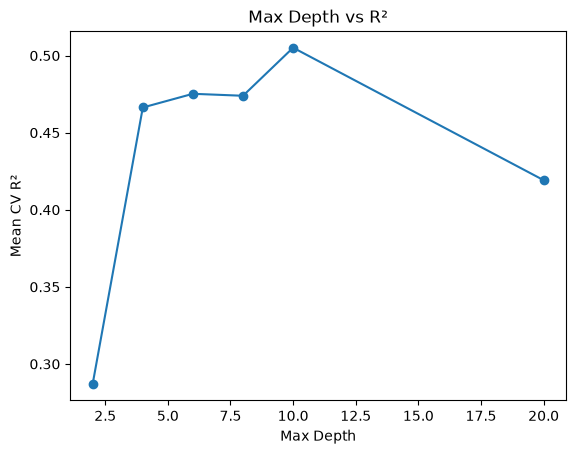

0.5572140940557031


In [10]:
df_depth = dfr[
    (dfr['param_model__min_samples_split'] == 5) &
    (dfr['param_model__min_samples_leaf'] == 1)
]

plt.plot(
    df_depth['param_model__max_depth'],
    df_depth['mean_test_r2'],
    marker='o'
)

plt.xlabel('Max Depth')
plt.ylabel('Mean CV R²')
plt.title('Max Depth vs R²')
plt.show()
print(mod1.best_score_)


In [7]:
df1

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,"313,000.00",3.00,1.50,1340,7912,1.50,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,"2,384,000.00",5.00,2.50,3650,9050,2.00,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,"342,000.00",3.00,2.00,1930,11947,1.00,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,"420,000.00",3.00,2.25,2000,8030,1.00,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,"550,000.00",4.00,2.50,1940,10500,1.00,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4544,2014-07-09,"308,166.67",3.00,1.75,1510,6360,1.00,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,204.08
4545,2014-07-09,"534,333.33",3.00,2.50,1460,7573,2.00,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,365.98
4546,2014-07-09,"416,904.17",3.00,2.50,3010,7014,2.00,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,138.51
4547,2014-07-10,"203,400.00",4.00,2.00,2090,6630,1.00,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,97.32


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import make_scorer, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler,FunctionTransformer
from sklearn.pipeline import Pipeline


df1 = pd.read_csv(r'D:\python\pandas_practice\data\modified_data.csv')

pd.set_option('display.float_format', '{:,.2f}'.format)

X = df1[['bedrooms','bathrooms','sqft_living','sqft_basement','floors','yr_built','city','statezip',
         'condition','sqft_lot','sqft_above','view','waterfront']]

# y = np.log(df1['price'])
y = df1['price']

X_train, X_test, Y_train, Y_tests = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), ["city",'statezip']),
        ('log', FunctionTransformer(np.log1p),['sqft_lot']),
    ],
    remainder="passthrough"
)

model = RandomForestRegressor()

piepline = Pipeline([("preprocessor", preprocessor),("model", model)])

"""If we use multiple param_grid then if we want to make a graph out of it we must have multiple graphs
because every parameter have there own size and the large size one will be used multiple time to fit it with
small size one """
mod = GridSearchCV(piepline,
                   param_grid={'model__max_depth':[2,4,6,8,10,20,30],
                               'model__min_samples_split': [2, 5, 10],
                               'model__min_samples_leaf': [1, 2, 5, 10]},
                   scoring= {'r2':make_scorer(r2_score)},
                   refit='r2',
                   cv=15,
                   n_jobs=-1)

mod.fit(X_train,Y_train)
mod.predict(X_test)

df1_r = pd.DataFrame(mod.cv_results_)
mod.best_score_

np.float64(0.7021477615017884)

In [ ]:
for score in ['mean_test_r2']:
    plt.plot([depth for depth in df1_r['param_model__max_depth']],df1_r[score])
    plt.xlabel('Depth')
    plt.ylabel('R2')
    plt.show()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__max_depth,params,split0_test_r2,split1_test_r2,split2_test_r2,split3_test_r2,...,split8_test_r2,split9_test_r2,split10_test_r2,split11_test_r2,split12_test_r2,split13_test_r2,split14_test_r2,mean_test_r2,std_test_r2,rank_test_r2
0,0.53,0.06,0.02,0.00,2,{'model__max_depth': 2},0.43,0.49,0.50,0.56,...,0.43,0.33,0.36,0.44,0.41,0.42,0.47,0.42,0.06,7
1,0.77,0.03,0.02,0.00,4,{'model__max_depth': 4},0.54,0.60,0.57,0.64,...,0.54,0.42,0.49,0.63,0.48,0.57,0.59,0.54,0.06,6
2,1.27,0.05,0.02,0.00,6,{'model__max_depth': 6},0.59,0.66,0.70,0.71,...,0.61,0.50,0.57,0.67,0.57,0.64,0.66,0.61,0.07,5
3,1.93,0.05,0.02,0.00,8,{'model__max_depth': 8},0.62,0.71,0.69,0.69,...,0.66,0.56,0.61,0.68,0.62,0.72,0.70,0.64,0.07,4
4,2.74,0.06,0.02,0.00,10,{'model__max_depth': 10},0.69,0.72,0.76,0.75,...,0.69,0.55,0.64,0.66,0.64,0.74,0.72,0.66,0.07,3
5,7.02,0.12,0.02,0.00,20,{'model__max_depth': 20},0.68,0.77,0.81,0.75,...,0.74,0.60,0.69,0.71,0.68,0.80,0.74,0.70,0.07,1
6,8.07,0.94,0.02,0.00,30,{'model__max_depth': 30},0.71,0.78,0.81,0.78,...,0.71,0.59,0.67,0.66,0.68,0.79,0.76,0.70,0.08,2


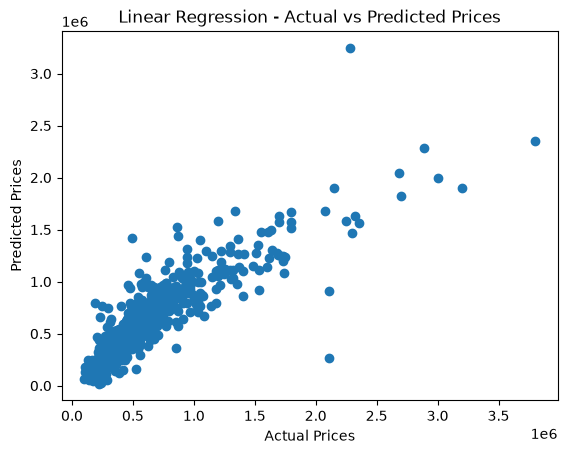

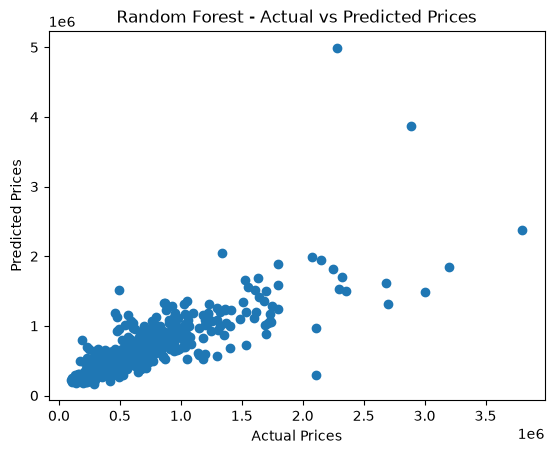

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import make_scorer, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler,FunctionTransformer
from sklearn.pipeline import Pipeline


df1 = pd.read_csv(r'D:\python\pandas_practice\data\modified_data.csv')
# df1 = df1[df1['price'] != 0]
# df1 = df1.drop(4346)
# df1 = df1.drop(4350)

""" so before adding price_per_sqft column in the X variable it was performing worse but after adding it improved there is drastic change

Before price_per_sqft:

    test R2 score: 0.03706860673595347
    training R2 score: 0.6039236929449974

After price_per_sqft:
    test R2 score: 0.42805726185500925
    training R2 score: 0.8713615857263574

data leakage:

price_per_sqft = price/sqt_living 

but we also need to know how price_per_sqft is calculated because if it was calculated by using price then there is data leakage
because model can derive the price value from price_per_sqft.

but if it was calculated not by using price then its good.

After data cleaning:
now model is performing well because i have cleaned the data

test R2 score: 0.7212335736380094
training R2 score: 0.7021500704757535
"""

pd.set_option('display.float_format', '{:,.2f}'.format)

X = df1[['bedrooms','bathrooms','sqft_living','sqft_basement','floors','yr_built','city','statezip',
         'condition','sqft_lot','sqft_above','view','waterfront']]

# y = np.log(df1['price'])
y = df1['price']

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), ["city",'statezip']),
        ('log', FunctionTransformer(np.log1p),['sqft_lot']),
        ("numerical", StandardScaler(), ["bedrooms","bathrooms","sqft_living","sqft_basement","floors","yr_built",
                                         "condition","sqft_above","view","waterfront"])
    ],
    remainder="passthrough"
)

model = {"Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(),
}
results=[]
for name,models in model.items():

    """pipline use to combine the preprocessor(like OneHotEncoder,StandardScaler) and model together so that we can
    use it in grid search"""
    piepline = Pipeline([("preprocessor", preprocessor),("model", models)])

    """So grid search used for to make combinations and find the best hyperparameter(is the value of a model that can 
    be changed for model to find best value) for the model but here we are not using any hyperparameter so it will just
    use the default hyperparameter of the model and it will also perform cross validation on the model to get the best
    model"""
    mod = GridSearchCV(piepline, 
                       param_grid={},
                       cv=15,
                       scoring={'r2':make_scorer(r2_score)},
                       refit = 'r2') # it take model,hyperparameter and cross validation value

    mod.fit(X_train,Y_train)
    prediction = mod.predict(X_test) #x values for the test data and it predict y value
    # score = r2_score(Y_test, prediction)#y value from test data and prediction is also y value (price) to calculate the R2 score
    # print(f'test R2 score {name}: {score}')
    results.append({'Model':model, 'R2':mod.best_score_})

    plt.scatter(Y_test, prediction)
    plt.xlabel("Actual Prices")
    plt.ylabel("Predicted Prices")
    plt.title(f"{name} - Actual vs Predicted Prices")
    plt.show()

# results_df = pd.DataFrame(results)    

# predict_train = model.predict(X_train)
# scorre = r2_score(Y_train, predict_train)

# print(f'training R2 score: {scorre}')


In [5]:
pd.DataFrame(results)


,Model,R2
0,"{'Linear Regression': LinearRegression(), 'Ran...",0.75
1,"{'Linear Regression': LinearRegression(), 'Ran...",0.70


MSE 124205.38949764904
RMSE 212126.92382504005
549470.3774367993
571818.5727142857 480000.0
4347   1,829,626.63
3729   1,741,390.26
4261   1,450,025.54
252    1,379,965.05
2772   1,292,399.63
122    1,214,804.65
2083   1,082,758.51
2978   1,052,572.32
3781     917,535.39
3959     825,261.74
Name: price, dtype: float64


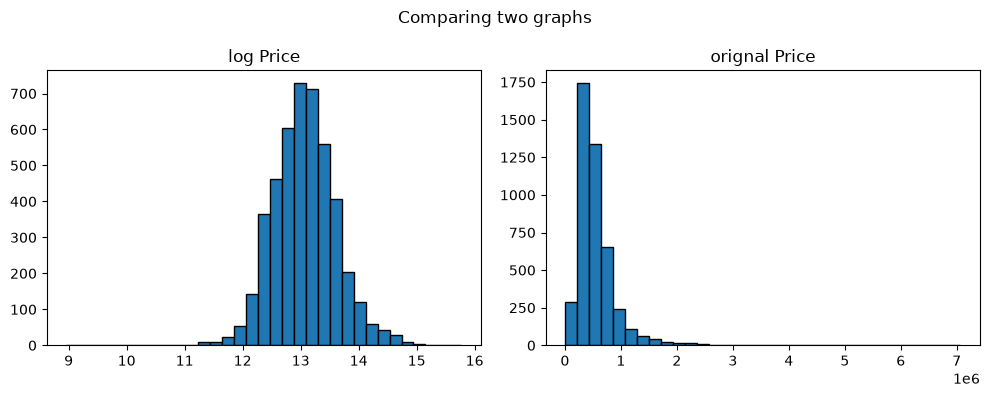

In [48]:
from sklearn.metrics import mean_absolute_error,root_mean_squared_error 

mse = mean_absolute_error(Y_test,prediction)
print('MSE',mse)

rmse = root_mean_squared_error(Y_test,prediction)
print('RMSE',rmse)
# print(Y_test.shape,prediction.shape,X_test.shape)
print(df1['price'].mean())
print(Y_test.mean(), Y_test.median())

errors = abs(Y_test - prediction)
print(errors.sort_values(ascending=False).head(10))


fig, ax = plt.subplots(1,2,figsize=(10,4))# row, column, figure size
ax[0].hist(np.log(df1['price']),bins =33,edgecolor='black')
ax[0].set_title('log Price')

ax[1].hist(df1['price'],bins =33,edgecolor='black')
ax[1].set_title('orignal Price')

fig.suptitle('Comparing two graphs')
plt.tight_layout()
plt.show()

# plt.boxplot(df1['price'])

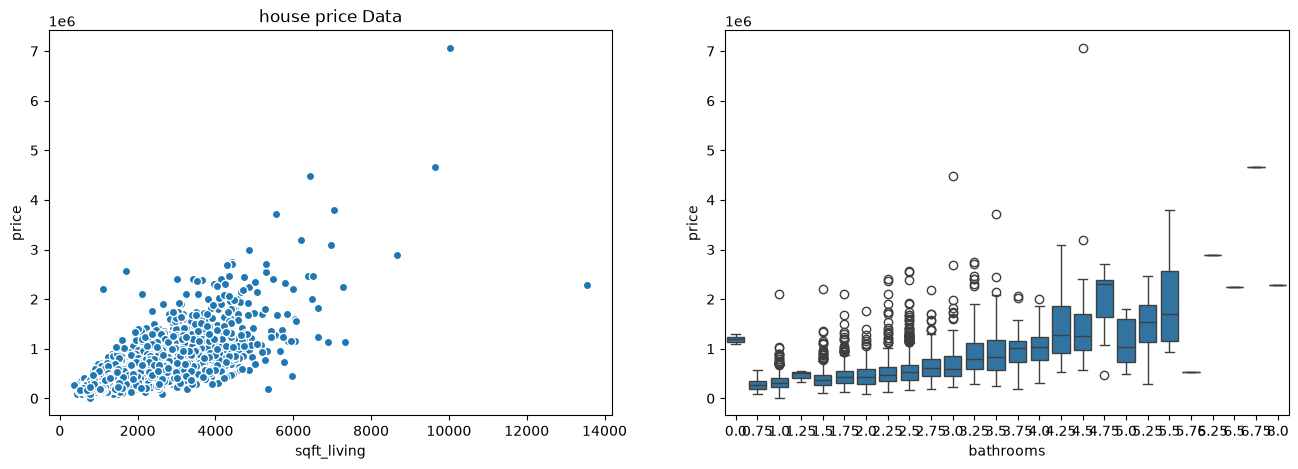

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


fig, ax = plt.subplots(1,2,figsize=(16,5))# row, column, figure size

ax[0].scatter(df1['sqft_living'],(df1['price']),edgecolor='white')
ax[0].set_xlabel('sqft_living')
ax[0].set_ylabel('price')
ax[0].set_title('house price Data')

sns.boxplot(x = 'bathrooms',y = 'price',data=df1)
# sns.heatmap(corr, annot=True)
plt.show()

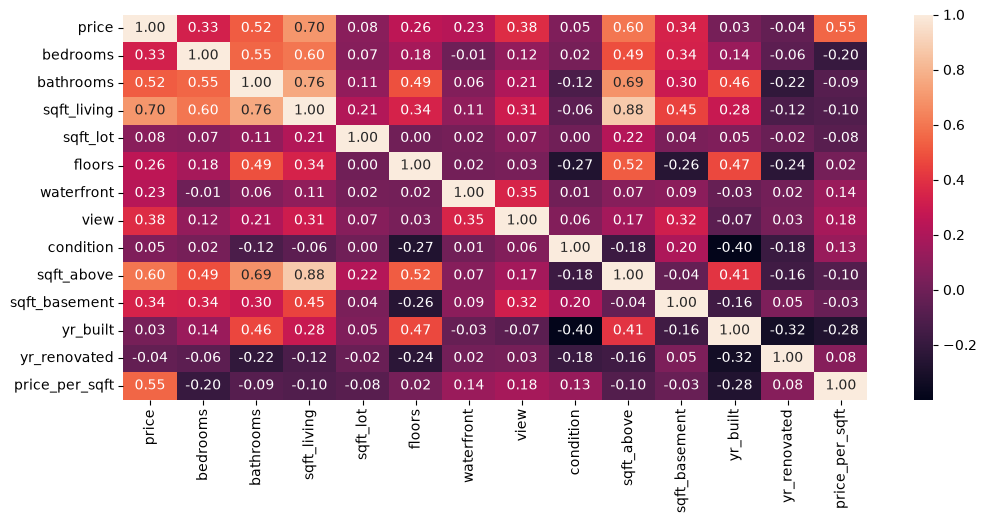

In [ ]:
plt.figure(figsize=(12,5))

"""so here we use (corr) it is corelation mean it measure corelation between every columns with (numbers as values)
and we use that in heatmap to plot it also"""

corr = df1.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f')
plt.show()

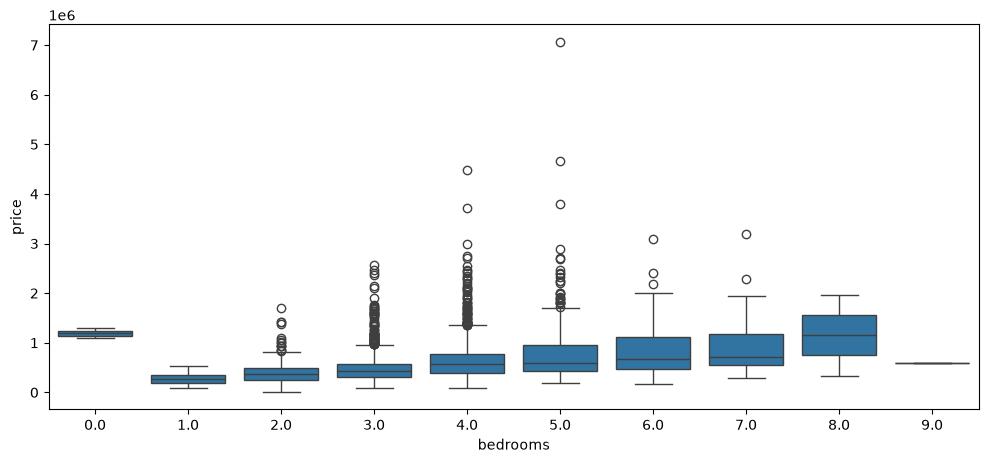

In [34]:
plt.figure(figsize=(12,5))
sns.boxplot(x = 'bedrooms',y = 'price',data=df1)
# sns.heatmap(corr, annot=True)
plt.show()

In [ ]:
city_price = df1.groupby('city')['price'].mean()
city_price

print('info')
df1.info()

print('Describe')
df1.describe()
# df1.info()


info
<class 'pandas.DataFrame'>
Index: 4549 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4549 non-null   str    
 1   price           4549 non-null   float64
 2   bedrooms        4549 non-null   float64
 3   bathrooms       4549 non-null   float64
 4   sqft_living     4549 non-null   int64  
 5   sqft_lot        4549 non-null   int64  
 6   floors          4549 non-null   float64
 7   waterfront      4549 non-null   int64  
 8   view            4549 non-null   int64  
 9   condition       4549 non-null   int64  
 10  sqft_above      4549 non-null   int64  
 11  sqft_basement   4549 non-null   int64  
 12  yr_built        4549 non-null   int64  
 13  yr_renovated    4549 non-null   int64  
 14  street          4549 non-null   str    
 15  city            4549 non-null   str    
 16  statezip        4549 non-null   str    
 17  price_per_sqft  4549 non-null   float64
dtyp

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price_per_sqft
count,"4,549.00","4,549.00","4,549.00","4,549.00","4,549.00","4,549.00","4,549.00","4,549.00","4,549.00","4,549.00","4,549.00","4,549.00","4,549.00","4,549.00"
mean,"549,470.38",3.39,2.15,"2,132.57","14,837.59",1.51,0.01,0.23,3.45,"1,822.42",310.15,"1,970.79",808.48,262.61
std,"368,230.65",0.90,0.78,956.06,"35,971.80",0.54,0.08,0.77,0.68,854.58,462.04,29.76,979.40,111.74
min,"7,800.00",0.00,0.00,370.00,638.00,1.00,0.00,0.00,1.00,370.00,0.00,"1,900.00",0.00,10.00
25%,"326,100.00",3.00,1.75,"1,460.00","5,000.00",1.00,0.00,0.00,3.00,"1,190.00",0.00,"1,951.00",0.00,182.85
50%,"465,000.00",3.00,2.25,"1,970.00","7,680.00",1.50,0.00,0.00,3.00,"1,590.00",0.00,"1,976.00",0.00,245.41
75%,"657,500.00",4.00,2.50,"2,610.00","10,970.00",2.00,0.00,0.00,4.00,"2,300.00",600.00,"1,997.00","1,999.00",315.57
max,"7,062,500.00",9.00,8.00,"13,540.00","1,074,218.00",3.50,1.00,4.00,5.00,"9,410.00","4,820.00","2,014.00","2,014.00","1,964.20"


In [4]:
print('Cities:',df1['city'].nunique())
print('Streets:',df1['street'].nunique())
print('State zips:',df1['statezip'].nunique())

print(Y_train.describe())
print('\n')
print(Y_test.describe())

Cities: 44
Streets: 4474
State zips: 77
count       3,639.00
mean      543,881.79
std       359,135.25
min         7,800.00
25%       326,991.67
50%       462,000.00
75%       655,137.50
max     7,062,500.00
Name: price, dtype: float64


count         910.00
mean      571,818.57
std       401,989.13
min       100,000.00
25%       325,000.00
50%       480,000.00
75%       663,750.00
max     3,800,000.00
Name: price, dtype: float64


# KNN

# There are catagorial and regression models 
- catogrial only give output in True or False just that
- regression predict values

In [1]:
import pandas as pd
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

df1 = pd.read_csv(r'D:\python\pandas_practice\data\modified_data.csv')
df1 = df1[df1['price'] != 0]
df1 = df1.drop(4346)
df1 = df1.drop(4350)

x = df1[['bedrooms','bathrooms','sqft_living','sqft_basement','floors','yr_built','city','statezip',
         'condition','sqft_lot','sqft_above','view','waterfront']]

y = df1['price']

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), ["city",'statezip'])
    ],
    remainder="passthrough"
)

X_train, X_test, Y_train, Y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", KNeighborsRegressor(n_neighbors=7))
])


model.fit(X_train,Y_train)


prediction = model.predict(X_test)
r_score = r2_score(Y_test,prediction)
print(f'test R2 score: {r_score}')


prediction = model.predict(X_train)
r_score_train = r2_score(Y_train,prediction)
print(f'train R2 score: {r_score_train}')

test R2 score: 0.4100715685645122
train R2 score: 0.5540187152986165


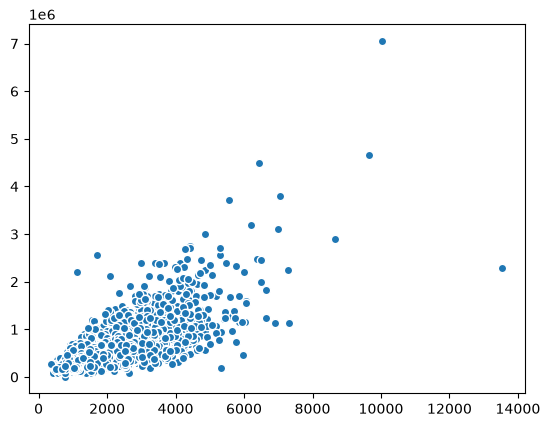

In [11]:
import matplotlib.pyplot as plt

x = df1['sqft_living']

y1 = df1['price']
y2 = df1['sqft_above']

plt.scatter(x, y1,edgecolors='white')

# Logistic Regression

In [1]:
import pandas as pd

df2 = pd.read_csv(r'D:\python\pandas_practice\data\ev_battery_failure_dataset.csv')
df2.describe()
df2['vehicle_brand'].isnull().sum()
df2['manufacturing_year'].isnull().median()
miss = df2.isnull().sum()
df2.shape

miss_percentage = (miss/len(df2))*100
miss_percentage


missing_info = pd.DataFrame({
    'missing_count': miss,
    'missing_percent': miss_percentage
})


missing_info.to_string()

number_data = df2.select_dtypes(include = 'number').columns
sting_data = df2.select_dtypes(include = 'string').columns

df2['manufacturing_year'].median()
df2['manufacturing_year']=df2['manufacturing_year'].fillna(float(df2['manufacturing_year'].median()))
df2['thermal_health_score'].isnull().sum()

df2[number_data] = df2[number_data].fillna(df2[number_data].median())

df2[sting_data] = df2[sting_data].fillna('Unknown')

df2.isnull().sum()

df2['manufacturing_year'].info()
df2_1 = df2.copy()
# df2_1.drop()
df2_1['odometer_km']

<class 'pandas.Series'>
RangeIndex: 200000 entries, 0 to 199999
Series name: manufacturing_year
Non-Null Count   Dtype  
--------------   -----  
200000 non-null  float64
dtypes: float64(1)
memory usage: 1.5 MB


0          98163.0
1         113600.0
2         242253.0
3          83700.0
4          88784.0
            ...   
199995    182311.0
199996    275317.0
199997    158747.0
199998     95122.0
199999     54982.0
Name: odometer_km, Length: 200000, dtype: float64

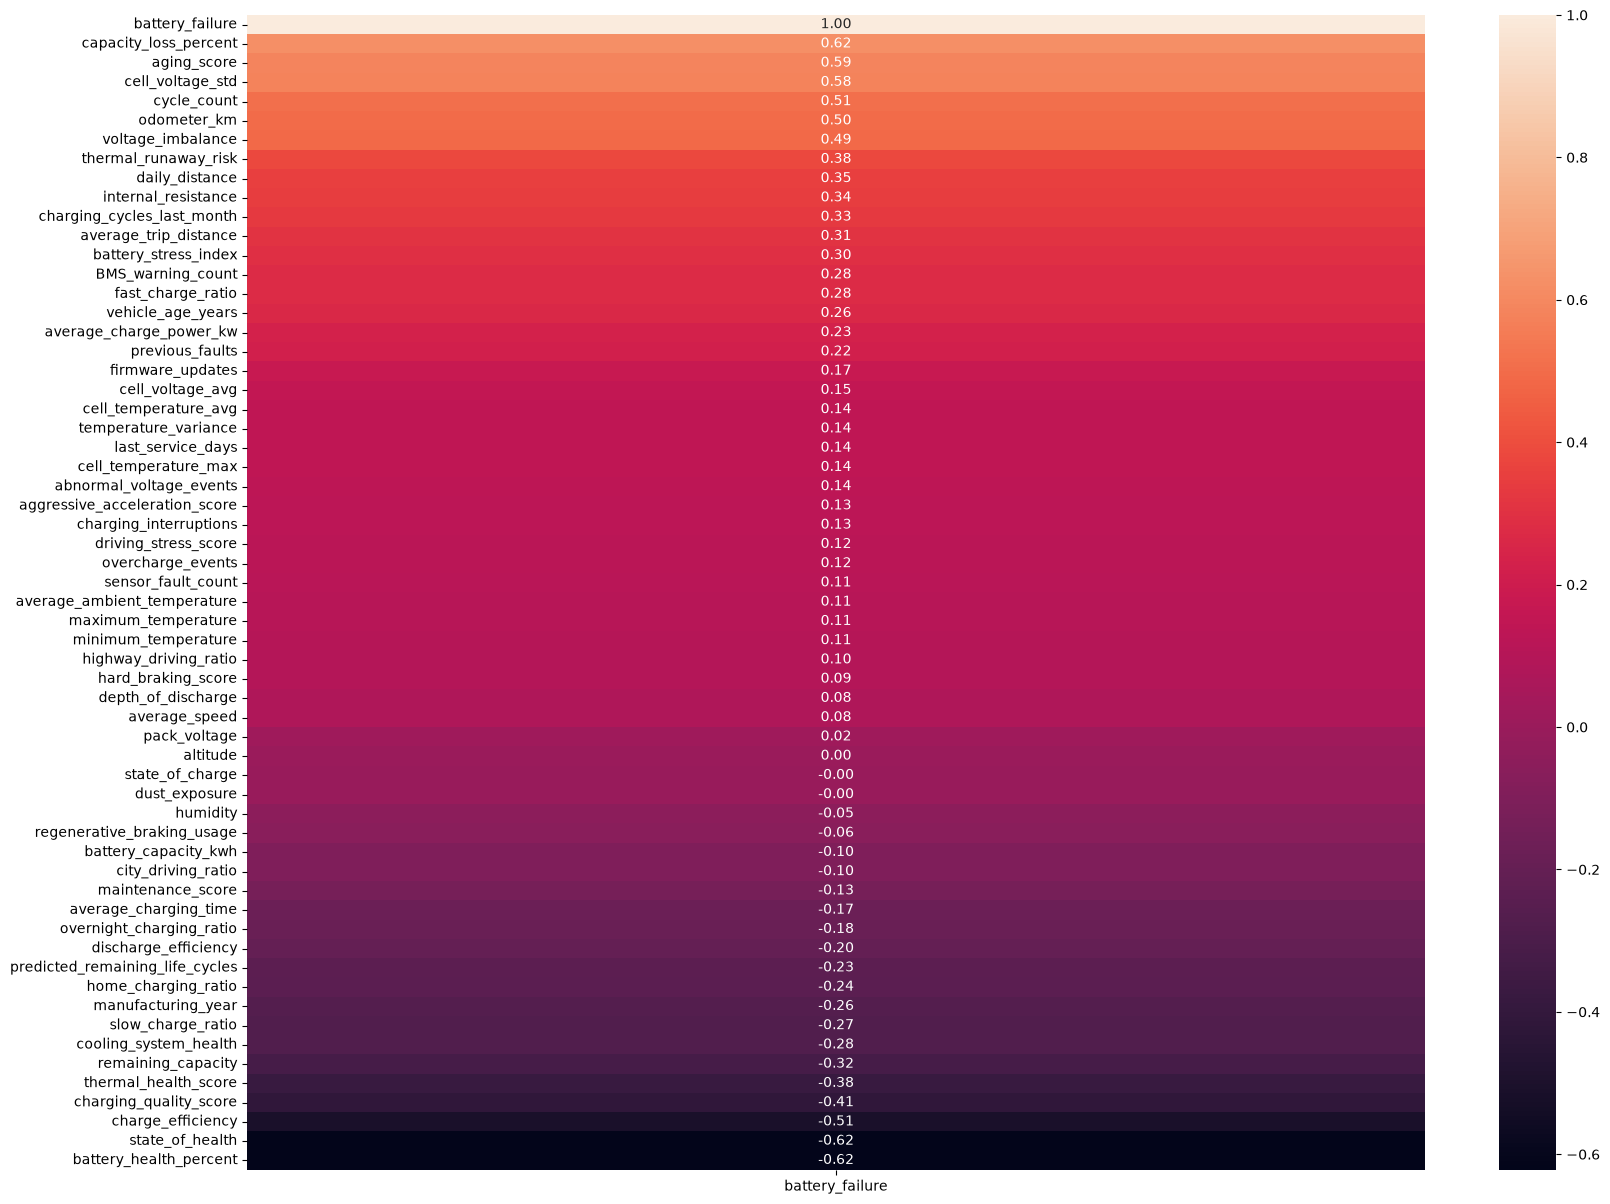

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# plt.figure(figsize=(12,15))
"""so here we use (corr) it is corelation mean it measure corelation between every columns with (numbers as values)
and the one we need that specific columns also can be called like we did here with (battery_faliure)"""


corrd = df2_1.corr(numeric_only=True)

battery_faliure = corrd['battery_failure'].sort_values(ascending=False)
# print(battery_faliure)
# print(battery_faliure.to_frame())
fig, ax = plt.subplots(figsize=(19,15))# row, column, figure size

# ax[0].scatter(df2_1['capacity_loss_percent'],df2_1['aging_score'])
# plt.scatter(df2_1['capacity_loss_percent'],df2_1['aging_score'])
sns.heatmap(battery_faliure.to_frame(), annot=True, fmt='.2f')
plt.show()

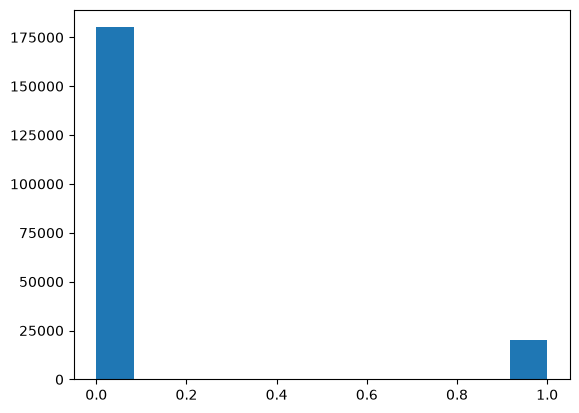

In [6]:
import matplotlib.pyplot as plt
plt.hist(df2_1['battery_failure'],bins=12)
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import make_scorer,precision_score,recall_score,f1_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt 

"""
Do I want the best balance?" → F1

I absolutely want to catch as many faults as possible? → Recall

I don't want too many false alarms? → Precision
"""

X = df2_1[['capacity_loss_percent','cell_voltage_std','cell_temperature_avg','cycle_count','odometer_km','voltage_imbalance',
      'thermal_runaway_risk','battery_stress_index','previous_faults','BMS_warning_count',
      'fast_charge_ratio','vehicle_age_years','average_charge_power_kw','aging_score','average_trip_distance',
      'daily_distance','internal_resistance','charging_cycles_last_month']]

y = df2_1['battery_failure']
x_train,x_test,y_train,y_test = train_test_split(
                                    X,
                                    y,
                                    test_size=0.2,
                                    random_state=42)


pipeline = Pipeline([('preprocess',StandardScaler()),
                     ('model',LogisticRegression(max_iter = 1000,class_weight='balanced'))])

grid = GridSearchCV(pipeline,
                    param_grid={'model__class_weight': [{0:1,1:2},
                                                        {0:1,1:3},
                                                        {0:1,1:4},
                                                        {0:1,1:5}]},
                    cv=10,
                    scoring={'precision_score':make_scorer(precision_score),
                             'recall_score':make_scorer(recall_score),
                             'f1_score':make_scorer(f1_score)},
                    refit='recall_score',# it take model,hyperparameter and cross validation value
                    n_jobs=-1) 

grid.fit(x_train, y_train)
prediction = grid.predict(x_test)


pd.DataFrame(grid.cv_results_)
# pipeline.get_params()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__class_weight,params,split0_test_precision_score,split1_test_precision_score,split2_test_precision_score,split3_test_precision_score,split4_test_precision_score,split5_test_precision_score,split6_test_precision_score,split7_test_precision_score,split8_test_precision_score,split9_test_precision_score,mean_test_precision_score,std_test_precision_score,rank_test_precision_score,split0_test_recall_score,split1_test_recall_score,split2_test_recall_score,split3_test_recall_score,split4_test_recall_score,split5_test_recall_score,split6_test_recall_score,split7_test_recall_score,split8_test_recall_score,split9_test_recall_score,mean_test_recall_score,std_test_recall_score,rank_test_recall_score,split0_test_f1_score,split1_test_f1_score,split2_test_f1_score,split3_test_f1_score,split4_test_f1_score,split5_test_f1_score,split6_test_f1_score,split7_test_f1_score,split8_test_f1_score,split9_test_f1_score,mean_test_f1_score,std_test_f1_score,rank_test_f1_score
0,1.184917,0.044623,0.035148,0.010488,"{0: 1, 1: 2}","{'model__class_weight': {0: 1, 1: 2}}",0.744331,0.751452,0.762258,0.752847,0.743848,0.746946,0.749429,0.765125,0.748581,0.757925,0.752274,0.006942,1,0.829438,0.817435,0.844599,0.835123,0.840177,0.811118,0.829438,0.814394,0.832702,0.830177,0.828460,0.010417,4,0.784583,0.783056,0.801319,0.791854,0.789083,0.777710,0.787406,0.788991,0.788404,0.792407,0.788481,0.005950,1
1,1.083506,0.066799,0.039795,0.005954,"{0: 1, 1: 3}","{'model__class_weight': {0: 1, 1: 3}}",0.697943,0.707748,0.707168,0.714951,0.697791,0.691402,0.698741,0.715336,0.702990,0.717573,0.705164,0.008401,2,0.878711,0.859760,0.878711,0.873026,0.878080,0.853443,0.876184,0.859848,0.875631,0.866162,0.869956,0.008905,3,0.777964,0.776383,0.783662,0.786121,0.777622,0.763924,0.777466,0.780963,0.779871,0.784897,0.778887,0.005926,2
2,1.176715,0.099762,0.039889,0.006281,"{0: 1, 1: 4}","{'model__class_weight': {0: 1, 1: 4}}",0.669027,0.673372,0.672000,0.678690,0.658356,0.654350,0.666046,0.680616,0.668862,0.679173,0.670049,0.008283,3,0.895136,0.888187,0.902085,0.903348,0.900821,0.883765,0.903348,0.893308,0.897727,0.891414,0.895914,0.006410,2,0.765739,0.766004,0.770227,0.775068,0.760736,0.751948,0.766756,0.772591,0.766577,0.770953,0.766660,0.006244,3
3,0.936578,0.223419,0.023482,0.007910,"{0: 1, 1: 5}","{'model__class_weight': {0: 1, 1: 5}}",0.640177,0.645524,0.638901,0.649866,0.634338,0.630742,0.644053,0.650586,0.645147,0.655204,0.643454,0.007167,4,0.915982,0.906507,0.910929,0.920404,0.917246,0.902085,0.923563,0.910985,0.914773,0.914141,0.913661,0.006025,1,0.753638,0.754073,0.751042,0.761830,0.750000,0.742397,0.758889,0.759074,0.756658,0.763310,0.755091,0.005936,4


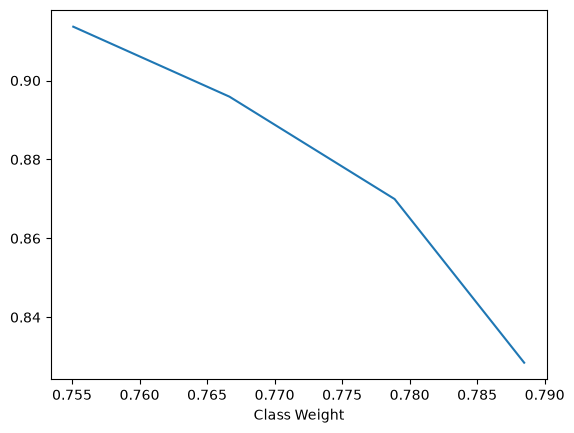

In [29]:
result = pd.DataFrame(grid.cv_results_)
plt.plot(result['mean_test_f1_score'], result['mean_test_recall_score'] )
plt.xlabel('Class Weight')
plt.show()

In [6]:
print(df2['battery_failure'].value_counts())
print(df2['battery_failure'].value_counts(normalize=True))

battery_failure
0    180079
1     19921
Name: count, dtype: int64
battery_failure
0    0.900395
1    0.099605
Name: proportion, dtype: float64


In [ ]:
from sklearn.metrics import make_scorer,precision_score,recall_score,f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt 
import numpy as np

"""
Do I want the best balance?" → F1

"I absolutely want to catch as many faults as possible?" → Recall

"I don't want too many false alarms?" → Precision
"""

X = df2_1[['capacity_loss_percent','cell_voltage_std','cycle_count','odometer_km','voltage_imbalance',
      'thermal_runaway_risk','battery_stress_index','previous_faults','BMS_warning_count',
      'fast_charge_ratio','vehicle_age_years','average_charge_power_kw','aging_score','average_trip_distance',
      'daily_distance','internal_resistance','charging_cycles_last_month']]

y = df2_1['battery_failure']
x_train,x_test,y_train,y_test = train_test_split(
                                    X,
                                    y,
                                    test_size=0.2,
                                    random_state=42)


pipeline = Pipeline([('preprocess',StandardScaler()),
                     ('model',LogisticRegression(max_iter = 1000,class_weight='balanced'))])

grid = GridSearchCV(pipeline,
                    param_grid={'model__class_weight': [{0:1,1:v}for v in np.linspace(1,20,30)]},#np.linspace(1,20,30) will create 30 values between 1 and 20
                    cv=10,
                    scoring={'precision_score':make_scorer(precision_score),
                             'recall_score':make_scorer(recall_score),
                             'f1_score':make_scorer(f1_score)},
                    refit='recall_score',# it take model,hyperparameter and cross validation value
                    n_jobs=-1) 

grid.fit(x_train, y_train)
prediction = grid.predict(x_test)


dff = pd.DataFrame(grid.cv_results_)

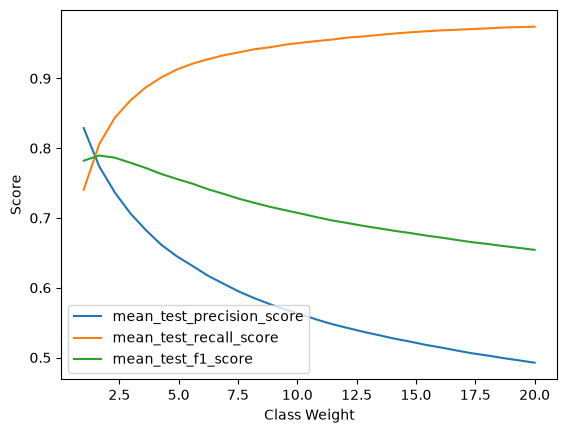

In [15]:
for score in ['mean_test_precision_score','mean_test_recall_score','mean_test_f1_score']:
    plt.plot([weight[1] for weight in dff['param_model__class_weight']], dff[score], label=score)

plt.xlabel('Class Weight')
plt.ylabel('Score')
plt.legend()
plt.show()

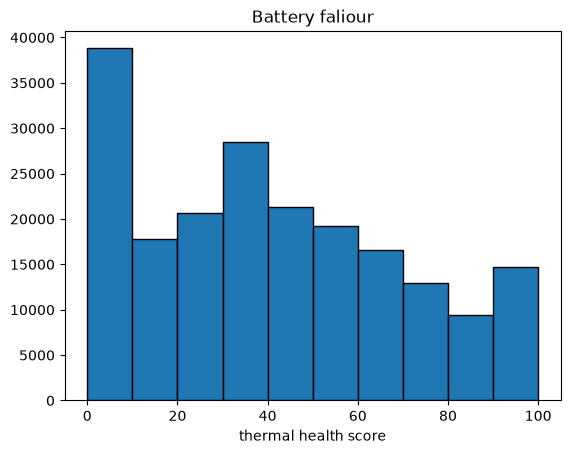

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 70 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   vehicle_id                       200000 non-null  str    
 1   vehicle_brand                    200000 non-null  str    
 2   vehicle_model                    200000 non-null  str    
 3   vehicle_type                     200000 non-null  str    
 4   manufacturing_year               200000 non-null  float64
 5   battery_manufacturer             200000 non-null  str    
 6   battery_chemistry                200000 non-null  str    
 7   battery_capacity_kwh             200000 non-null  float64
 8   drive_type                       200000 non-null  str    
 9   odometer_km                      200000 non-null  float64
 10  vehicle_age_years                200000 non-null  float64
 11  fleet_or_private                 200000 non-null  str    
 12  battery_seria

In [9]:
import matplotlib.pyplot as plt

plt.hist(df2['driving_stress_score'],bins=10,edgecolor='black')
plt.xlabel('thermal health score')
plt.title('Battery faliour')

plt.show()

df2_1.info()

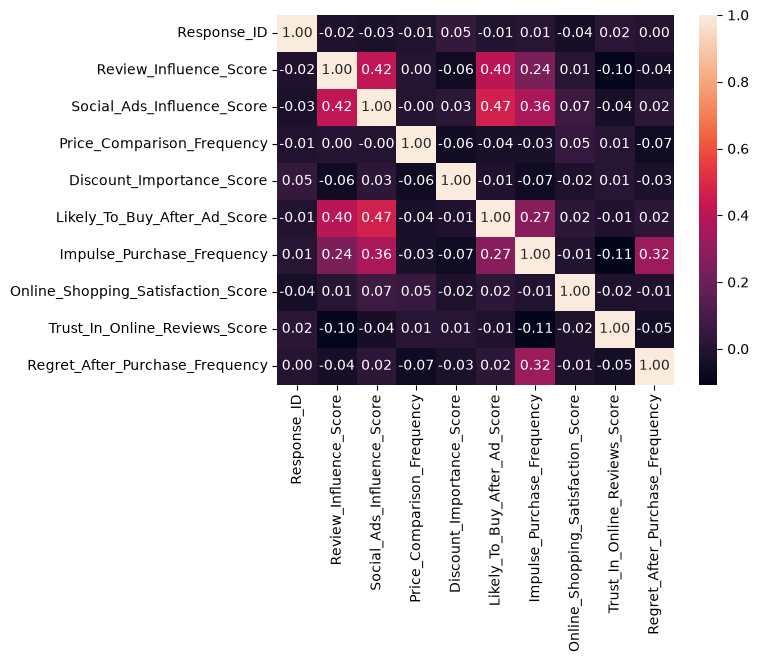

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df4 = pd.read_csv(r'D:\python\pandas_practice\data\consumer_shopping_behavior_survey.csv')
df4.isnull().sum()
number_only = df4.select_dtypes(include = 'number')
number_only.fillna(number_only.median(),inplace = True)
number_only.isnull().sum()

stringg = df4.select_dtypes(include = 'string')
stringg.fillna('Unknown',inplace = True)
stringg.isnull().sum()
df4

corr = df4.corr(numeric_only = True)
sns.heatmap(corr,annot = True,fmt = '.2f')

plt.show()

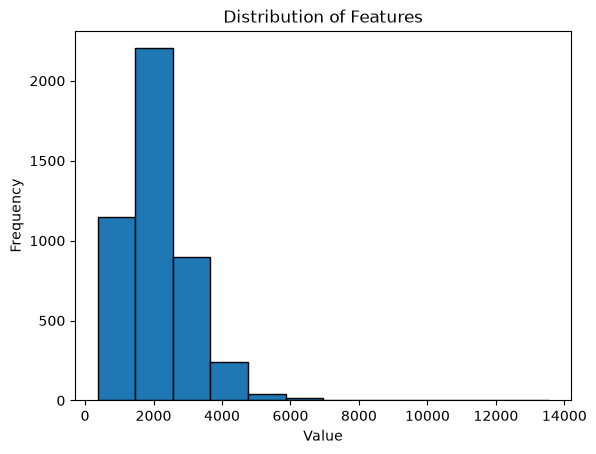

In [29]:
a = df1[['sqft_living']]

plt.hist(a,bins=12, edgecolor='black')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Distribution of Features')
plt.show()